# Sesión 06 — Random Forest, Gradient Boosting y boosting moderno

**Bloque:** 2 · Regresión

## Objetivos

Al terminar esta sesión deberías ser capaz de:

- Explicar en qué se diferencian *bagging* y *boosting* sin recurrir a la fórmula: qué hace cada uno con los árboles y por qué funciona.
- Justificar por qué promediar muchos árboles inestables produce un modelo estable.
- Ajustar `n_estimators` y `learning_rate` entendiendo que están acoplados, y predecir qué pasa si mueves uno solo.
- Comparar modelos por **rendimiento y por coste** —tiempo de entrenamiento— y defender una elección que tenga en cuenta los dos.
- Usar XGBoost, LightGBM y CatBoost, y saber decir qué aporta cada uno frente al `GradientBoostingRegressor` de scikit-learn.
- Reconocer cuándo merece la pena tratar las variables categóricas de forma nativa en vez de con `get_dummies`.

## Qué necesitas de antes

- **S05**: árboles de regresión, `max_depth`, sobreajuste y `GridSearchCV`. Un ensemble no es más que muchos árboles de S05 puestos de acuerdo.
- **S04**: validación cruzada.
- Tus RMSE de S04 y S05 sobre **California** y sobre **Ames**. Hoy se cierra la tabla del bloque entero.

## Librerías

Además del stack de siempre, esta sesión usa **`xgboost`**, **`lightgbm`** y **`catboost`**. Si no los tienes:

```
pip install xgboost lightgbm catboost
```

## 1. Random Forest: muchos árboles mediocres, una buena decisión

En S05 quedó una pega: un árbol es **inestable**. Cambia unas pocas filas del entrenamiento y el árbol se reorganiza entero. Un modelo así acierta o falla según qué datos le tocaron, que es justo lo que no queremos.

El **Random Forest** ataca esa inestabilidad de la forma más simple posible: en vez de un árbol, entrena **muchos** y promedia sus predicciones. La estrategia se llama ***bagging*** (*bootstrap aggregating*) y tiene dos ingredientes:

1. **Cada árbol ve un remuestreo distinto** de los datos de entrenamiento (filas sacadas al azar con reemplazo).
2. **Cada corte considera solo un subconjunto al azar de las variables** (`max_features`), para que los árboles no se parezcan demasiado entre sí.

La clave está en el promedio. Cada árbol individual se equivoca, pero **se equivoca en una dirección distinta**, porque ha visto datos distintos. Al promediar, los errores aleatorios se cancelan y queda la señal común. Por eso funciona: no porque cada árbol sea bueno, sino porque sus errores son independientes.

Hiperparámetros que importan:

- **`n_estimators`** — cuántos árboles. **Más nunca empeora**; solo cuesta tiempo, con rendimientos decrecientes. Esto es específico de *bagging* y no vale para *boosting*.
- **`max_depth`, `min_samples_leaf`** — los de S05, aplicados a cada árbol del bosque.
- **`max_features`** — cuántas variables puede mirar cada corte. Bajarlo hace los árboles más distintos entre sí, que es de donde sale la ganancia.

**Qué problema resuelve:** la varianza. Un modelo que depende demasiado de qué filas concretas vio.

**Cuándo elegirlo:** como primer modelo serio en casi cualquier problema tabular. Da un resultado muy digno sin tocar nada, es difícil de estropear y se paraleliza sin esfuerzo, porque los árboles son independientes.

**Cuándo NO:** cuando necesitas explicar la decisión —ya no hay un árbol que enseñar—, cuando la predicción tiene que ser muy rápida, o cuando el problema es de verdad lineal.

**Qué asume:** lo mismo que un árbol, es decir, casi nada. Hereda también sus límites: no extrapola fuera del rango visto.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")

### Demostración: el bosque contra el árbol

Un dataset de juguete: una curva seno con ruido añadido. Sabemos cuál es la señal verdadera, así que podemos ver quién la encuentra y quién persigue el ruido.

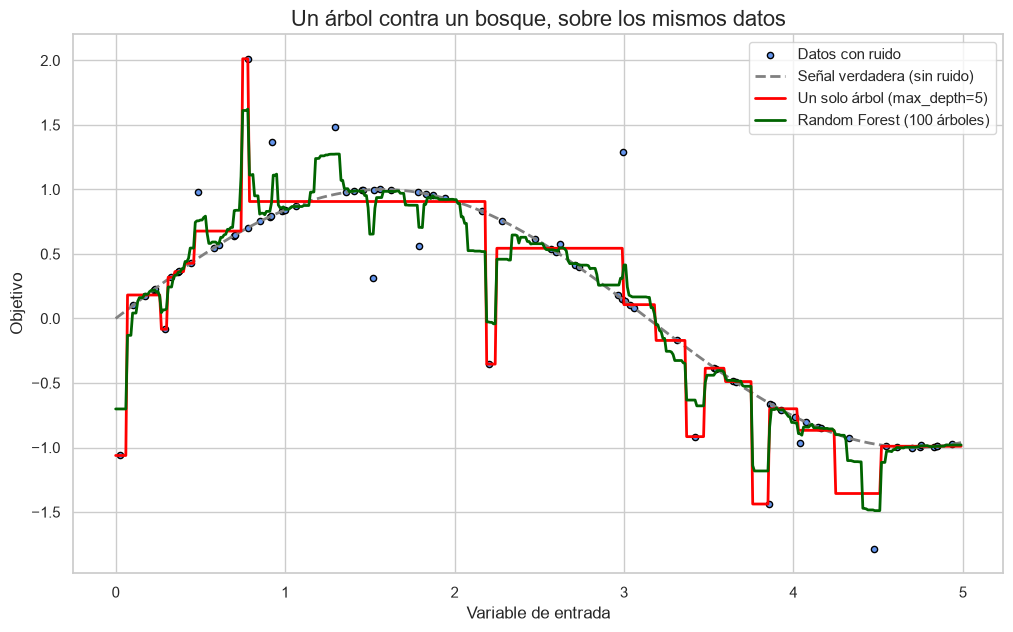

In [3]:
# Datos de juguete: una curva seno con ruido en uno de cada cinco puntos
rng = np.random.RandomState(42)
X_juguete = np.sort(5 * rng.rand(80, 1), axis=0)
y_juguete = np.sin(X_juguete).ravel()
y_juguete[::5] += 3 * (0.5 - rng.rand(16))

# Un árbol solo, con margen de sobra para sobreajustar
arbol = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_juguete, y_juguete)

# Un bosque de 100 árboles sobre los mismos datos
bosque = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_juguete, y_juguete)

rejilla = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]

plt.figure(figsize=(12, 7))
plt.scatter(X_juguete, y_juguete, s=20, edgecolor="black", c="cornflowerblue",
            label="Datos con ruido")
plt.plot(rejilla, np.sin(rejilla), color="gray", linestyle="--", lw=2,
         label="Señal verdadera (sin ruido)")
plt.plot(rejilla, arbol.predict(rejilla), color="red", lw=2,
         label="Un solo árbol (max_depth=5)")
plt.plot(rejilla, bosque.predict(rejilla), color="darkgreen", lw=2,
         label="Random Forest (100 árboles)")
plt.xlabel("Variable de entrada")
plt.ylabel("Objetivo")
plt.title("Un árbol contra un bosque, sobre los mismos datos", fontsize=16)
plt.legend()
plt.show()

**Qué se ve.** La línea gris discontinua es la señal verdadera, el seno limpio: es lo que un modelo perfecto debería encontrar.

La **roja** es el árbol único. Se lanza a por cada punto, incluidos los que solo son ruido, y produce esa silueta de escalones bruscos. Ha confundido el ruido con información.

La **verde** es el bosque. Está claramente más cerca del seno verdadero. Y lo notable es que **cada uno de sus 100 árboles es tan malo como el rojo**: ninguno mejoró. Lo que mejora es el promedio, porque cada árbol vio un remuestreo distinto y por tanto se equivocó en un sitio distinto. Al sumarlos, los errores se compensan y sobrevive lo que todos tienen en común, que es la señal.

Fíjate en que la verde sigue siendo escalonada, no suave: sigue siendo una suma de árboles, con sus límites. Y en los extremos ninguna de las dos extrapola.

---
### Preguntas de recap — Random Forest

1. ¿Qué problema de los árboles individuales resuelve el Random Forest?
2. ¿Por qué hace falta que cada árbol vea datos distintos? ¿Qué pasaría si todos vieran lo mismo?
3. ¿Qué controla `max_features` y por qué bajarlo puede mejorar el modelo?
4. ¿Puedes subir `n_estimators` sin miedo a sobreajustar? ¿Qué te cuesta subirlo?
5. En la demostración, ningún árbol del bosque es mejor que el árbol rojo. ¿Cómo puede el conjunto ser mejor que cualquiera de sus partes?

-1 El rnaodm forest a diferencia de los arboles individuales no le da tanta importancia al ruido y no se intenta adaptar a el ya que tenemos muchos arboles haciendo diferentes preguntas que despues se hara media, si un arbol se enfoca en una variable que no toca, despues con la media de otro abroles corrergiremos el error

-2 Si todos vieran lo mismo tendriamos el mismo arbol multiplicado por x, si ven diferentes variables tendremos diferentes resultados y se haria media con los diferentes tesuiltados que hemos obtenido 

-3 Controla cuantas variables contiene cada arbol, bajarlo hace que los arboles sean mas dirferentes entre si

-4 Si, el unico miedo que podemso tener con subir n_estiamators es el tiempo de computacion ya que podemos subirlo sin miedo, si lo subimos no tendremos sobreajuistye ya que tendremos todos los arboles con diferentes combinaciones de variables, ningun arbol seria idnetico a otro 

-5 Por la cancelacion de errores al sacar la media, el arbol a se foja en el ruido, el arbol b no, despues al hacer la media disminuimos la importancia de este ruido, uno se equivocan por arriba y otros por abajo y con la media nivelamos

---

## 2. Gradient Boosting: cada árbol arregla lo que rompió el anterior

El **Gradient Boosting** llega al mismo sitio por el camino contrario. En vez de entrenar árboles independientes y promediarlos, los entrena **en cadena**: cada árbol nuevo se dedica a predecir **los errores que aún quedan** del conjunto anterior.

El procedimiento, sin fórmulas:

1. Empieza con una predicción tonta (por ejemplo, la media de `y`).
2. Calcula en qué se ha equivocado: los **residuos**.
3. Entrena un árbol pequeño **para predecir esos residuos**.
4. Suma ese árbol a la predicción, multiplicado por un factor pequeño.
5. Vuelve al paso 2, ahora con los errores que quedan.

De ahí salen las dos diferencias prácticas frente a Random Forest:

- Los árboles de boosting son **deliberadamente débiles**: profundidad 3 o menos. No hacen falta buenos, hacen falta muchos y especializados.
- **`n_estimators` sí puede sobreajustar.** En *bagging* añadir árboles solo afina el promedio; aquí cada árbol añade una corrección, y si sigues corrigiendo acabas corrigiendo el ruido.

El hiperparámetro que manda es el **`learning_rate`**: el factor por el que se multiplica cada árbol antes de sumarlo. Cuanto más bajo, más pequeño el paso, más robusto el modelo... **y más árboles hacen falta para llegar**. `learning_rate` y `n_estimators` están acoplados: mover uno sin mover el otro suele empeorar las cosas. Lo comprobarás en el ejercicio.

**Qué problema resuelve:** el sesgo. Va reduciendo el error sistemático que queda, corrección a corrección.

**Cuándo elegirlo:** cuando quieres el mejor rendimiento posible en datos tabulares y estás dispuesto a ajustar. En la práctica, es lo que gana las competiciones de datos tabulares.

**Cuándo NO:** cuando no vas a ajustar nada (Random Forest da más por menos), cuando el entrenamiento tiene que ser rápido y no puedes usar las librerías modernas, o cuando hay mucho ruido en la variable objetivo — perseguir residuos ruidosos es perseguir ruido.

**Qué asume:** como el árbol, casi nada. Pero es bastante más sensible a sus hiperparámetros, y por tanto más fácil de estropear.

In [ ]:
# Boosting a mano, con dos árboles, sobre los mismos datos de juguete

# Árbol 1: deliberadamente débil (una sola pregunta)
arbol_1 = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_juguete, y_juguete)
pred_1 = arbol_1.predict(X_juguete)

# Lo que le queda por explicar: los residuos
residuos_1 = y_juguete - pred_1  # 1. Calculamos cuánto le ha faltado al Árbol 1 para acertar

# Árbol 2: NO predice y, predice el error del árbol 1
arbol_2 = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_juguete, residuos_1)
pred_2 = arbol_2.predict(X_juguete)

# La predicción combinada es la suma de las dos
pred_combinada = pred_1 + pred_2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.scatter(X_juguete, y_juguete, s=20, edgecolor="black", c="cornflowerblue",
            label="Datos reales")
ax1.plot(X_juguete, pred_1, color="red", lw=2, label="Predicción del árbol 1")
ax1.scatter(X_juguete, residuos_1, s=20, edgecolor="black", c="orange",
            label="Residuos: lo que falla el árbol 1")
ax1.axhline(0, color='gray', linestyle='--')
ax1.set_title("Paso 1: un árbol débil y lo que le sobra", fontsize=15)
ax1.legend()

ax2.scatter(X_juguete, y_juguete, s=20, edgecolor="black", c="cornflowerblue",
            label="Datos reales")
ax2.plot(X_juguete, pred_1, color="red", lw=1, alpha=0.5, label="Solo el árbol 1")
ax2.plot(X_juguete, pred_combinada, color="darkgreen", lw=2,
         label="Árbol 1 + árbol 2")
ax2.set_title("Paso 2: sumamos la corrección", fontsize=15)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"RMSE solo con el árbol 1:      {np.sqrt(np.mean(residuos_1 ** 2)):.3f}")
print(f"RMSE con los dos combinados:   {np.sqrt(np.mean((y_juguete - pred_combinada) ** 2)):.3f}")

**Qué se ve.**

En el gráfico de la izquierda, la línea roja es un árbol de profundidad 1: hace **una sola pregunta** y por tanto solo puede dar dos valores. Es malísimo a propósito. Los puntos naranjas son sus residuos, y lo importante es que **no son ruido aleatorio**: tienen forma. Esa forma es información que el árbol 1 no supo aprovechar y que, por tanto, todavía está disponible.

A la derecha, el árbol 2 —entrenado para predecir esos naranjas, no para predecir `y`— se suma al primero. La línea verde tiene ya cuatro escalones en vez de dos, y el RMSE baja.

Repite eso cien veces y tienes Gradient Boosting. Cada árbol es ridículo por separado; la cadena entera no lo es.

Dos matices sobre esta demostración simplificada: el modelo real multiplica cada árbol por el `learning_rate` antes de sumarlo, en vez de sumarlo entero como aquí; y arranca de la media de `y`, no del primer árbol. La idea es la que has visto.

---
### Preguntas de recap — Gradient Boosting

1. ¿En qué se diferencia el Gradient Boosting del Random Forest, en una frase?
2. ¿Qué predice exactamente el segundo árbol de un Gradient Boosting?
3. ¿Por qué los árboles de boosting se dejan a propósito poco profundos?
4. ¿Qué hace el `learning_rate` y por qué no se puede tocar sin mirar `n_estimators`?
5. ¿Por qué en boosting sí puede sobreajustar subir `n_estimators`, si en Random Forest no?

1- Gradient Boosting funciona arbolo por arbol, el arbol anterior mira el residuo del arobl anterior, rnadom forest se calcula todos a la vez y despues se calcula la media, random forest arboles profundos, gradient boosting poco profundos.

2- El segundo arbol en un gradient boosting mira el residuo que ha calcula el primero, la case vale 300.000, el primer arbol calcula que valen 200.000, el residuo es 100.000, el segundo arbol mira eso.

3- Se dejan poco profundos para aseurar que sean modelos debiles, si fueran propfundos, cada arbol sobreajuste los datos por si solo, al ser sencillo aportamn correcciones pequeñas y suaves que evitan memorizar el ruido 

4- El learning rate es un valor que le damos para reduir lo que dice el segundo arbol, el segndo alrbol actua sobre el resuido del primero y dice suma 10.000, con el laerging rate bajamos este numero, cuanto mas pequeño los pasitos son mas pequeños, 0.10 necesitas augmentar obligatoriamnete el numero n_estimators para llegar al optimo 

5- Se puede sobreajustar subiendo el n_estiamtors por que lso arboles actuan en cadena, en random_forest no ya que trabajan por separado hasta el final

---

---
## Ejercicio 1 — La gran comparativa

**Contexto.** Sigues en la inmobiliaria de California. Ya les entregaste un árbol ajustado en S05 y quedaron satisfechos. Ahora te preguntan si se puede hacer mejor, y el director de tecnología añade una condición: *"lo que sea, pero el modelo se reentrena cada noche y tiene que estar listo antes de que abramos"*. Es decir: **el tiempo de entrenamiento entra en la decisión**.

**Tu tarea.**
1. Prepara California como en S05: numéricas, nulos a la mediana, `train_test_split` con `random_state=42`. Los árboles no necesitan escalado.
2. Entrena `DecisionTreeRegressor`, `RandomForestRegressor` y `GradientBoostingRegressor` **con los parámetros por defecto** y `random_state=42`. Para cada uno mide **el RMSE en test y el tiempo de entrenamiento**.
3. Monta una tabla de pandas con las tres filas y las dos columnas.
4. Saca las `feature_importances_` de los tres y dibújalas en un gráfico de barras agrupadas, para ver si coinciden en qué importa.
5. Entrena otro `GradientBoostingRegressor` cambiando solo `learning_rate` a `0.01`. Compara su RMSE con el del modelo por defecto. Después prueba a subir `n_estimators` a 1000 manteniendo ese `learning_rate`, y mide también el tiempo.

**Criterio de que lo has hecho bien:** los tres modelos deben quedar claramente ordenados en RMSE, y **el orden por tiempo no es el mismo que el orden por acierto** — ahí está la decisión que te piden. En el punto 5, bajar el `learning_rate` a secas debería **empeorar mucho** las cosas; si te mejora, revisa el código. Al subir `n_estimators` deberías recuperar aproximadamente lo perdido, a un coste de tiempo que se nota.

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
import time
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import pandas as pd
import matplotlib.pyplot as plt

#------------PASO 1-----------------------------------------------------------------------------------------------------------
# 1. Cargar el dataset (todas las variables ya son numéricas)
california = fetch_california_housing(as_frame=True) # descarga el dataset y lo devuelve como un DataFrame de pandas
X = california.data   # guardamos las variables predictoras en X
y = california.target  # guardamos la variable objetivo en y

# 2. Imputar nulos a la mediana
imputer = SimpleImputer(strategy='median') # Si encuentras un valor nulo en alguna columna, calcula la mediana de esa columna y colócala ahí". Usamos la mediana porque es insensible a valores extremos (outliers).
X_prep = imputer.fit_transform(X) #aprende la mediana de cada columna de x, remplaza los nulos por esos valoresy aguarda el resutlado limpio en X_prep

# 3. Dividir en train y test (con random_state=42)
# IMPORTANTE: Los árboles se basan en ordenaciones/cortes, por lo que NO necesitan escalado
X_train, X_test, y_train, y_test = train_test_split(
    X_prep, y, test_size=0.2, random_state=42
)
# partimos para dividir entrrenamiento y testeo, 80% para entrenar y 20% para testear. random_state=42 para que siempre nos de la misma división


# ------------PASO 2-----------------------------------------------------------------------------------------------------------

# 1. Crear el diccionario con los 3 modelos por defecto (con random_state=42)
modelos = {
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}
# creeamos un diccionario con los tres modelos, guardamos en clave el nombre del modelo y en valor el modelo con sus hiperparametros por defecto, con random_state=42 para que siempre nos de los mismos resultados, es como la estrucutra,
# random state=42 es para que siempre nos de los mismos resultados, es como la semilla de aleatoriedad, para que siempre nos de la misma variaciones

# Diccionarios vacíos para guardar métricas y modelos
resultados = {}  #diccionario vacio para ir guardadno los datos metricos finales, el rsme en test y el tiempo de entrenamiento
modelos_entrenados = {} # creea un diccionario vaccio para ir guardando los objeto de los modelos entrenados 



# 2. Bucle para entrenar, medir tiempo y evaluar RMSE en test
for nombre, modelo in modelos.items():  # recorre el diccionario modelos, en la 1 vuelta, toma el arbolm en la 2 random forest y en la 3 gradient boosting
    # Cronometramos SOLO la fase de fit (entrenamiento)
    inicio = time.time() #captura el tiempo de inicio
    modelo.fit(X_train, y_train)  #ejecuta el entrenamiento del modelo con los datos de entrenamiento
    fin = time.time() #captura el segundo exacto en el que concluye el entrenamiento
    tiempo_entrenamiento = fin - inicio #resta el tiempo del inicio con el de fin para saber el tiempo exxacto 

    # este es el momento que hace el test el mdoelo
    
    # Predecimos en TEST y calculamos RMSE
    predicciones = modelo.predict(X_test) # el modelo calcula los precios de testeo con los datos de testeo, y guarda el resultado en predicciones
    rmse = np.sqrt(mean_squared_error(y_test, predicciones))#calcula la media de error al cuadrado entre los precios reales y los predichos, y luego le saca la raiz cuadrada para obtener el RMSE np.sqrt para la raiz cuadrada 

    # este es el momento en el que hace el examen
    
    # Guardamos el resultado de cada modelo
    resultados[nombre] = { #guarda un sub diccionario dentro de resultados organizando {'RMSE Test': 0.xx, 'Tiempo (s)': x.xx}
        'RMSE Test': rmse,
        'Tiempo (s)': tiempo_entrenamiento
    }
    modelos_entrenados[nombre] = modelo # guarda eñl modelo con su apredizaje en el diccionario modelos entrenados



# ------------PASO 3-----------------------------------------------------------------------------------------------------------
# Convertimos el diccionario de resultados en un DataFrame de Pandas
df_comparativa = pd.DataFrame.from_dict(resultados, orient='index') #orient='index': ¡Punto clave! Le indica a Pandas que las claves del diccionario (Decision Tree, Random Forest, Gradient Boosting) deben ser las filas (el índice de la tabla), y las claves internas (RMSE Test y Tiempo (s)) las columnas.

# Mostramos la tabla
df_comparativa


# ------------PASO 4-----------------------------------------------------------------------------------------------------------


# 1. Creamos una tabla con las importancias de cada modelo
# Usamos california.feature_names como índice (los nombres de las variables)
importancias = pd.DataFrame({
    'Decision Tree': modelos_entrenados['Decision Tree'].feature_importances_,
    'Random Forest': modelos_entrenados['Random Forest'].feature_importances_,
    'Gradient Boosting': modelos_entrenados['Gradient Boosting'].feature_importances_
}, index=california.feature_names)

# son una lista con numero por cada modelo, para ver que grado de importancia le han dado a casa columna, [0.52, 0.12, 0.05, 0.03, 0.04, 0.08, 0.10, 0.06] por modelo
# con el index california.feature_names es la lista con los nombres reales de las variables: ['MedInc', 'HouseAge', 'AveRooms', ...].

# 2. Dibujamos el gráfico de barras agrupadas
importancias.plot(kind='bar', figsize=(12, 6)) # Hacer el dibujo agrupado
plt.title('Importancia de las variables según cada modelo')
plt.ylabel('Importancia (suma 1.0)')
plt.xlabel('Variables del dataset')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# ------------PASO 5-----------------------------------------------------------------------------------------------------------
# 1. Modelo con learning_rate bajo (0.01) y árboles por defecto (100)
gb_lento = GradientBoostingRegressor(learning_rate=0.01, random_state=42)

#definimos el modelo con el leaning rate y random state

inicio = time.time()  #iniciamos el tiempo
gb_lento.fit(X_train, y_train) #entrenamos al modelo con los datos que separamos
fin = time.time() #finalizamos el tiempo 
tiempo_lento = fin - inicio # restamos el tiempo 

pred_lento = gb_lento.predict(X_test) #hacemos la predicción con los datos de examen y guardamos el resultado en pred_lento
rmse_lento = np.sqrt(mean_squared_error(y_test, pred_lento)) #calculamos el rmse con los datos de examen y los predichos por el modelo

# 2. Modelo con learning_rate bajo (0.01) y subiendo árboles a 1000
gb_compensado = GradientBoostingRegressor(learning_rate=0.01, n_estimators=1000, random_state=42) # lo mismo que antes pero ponemos 1000 arboles

inicio = time.time()
gb_compensado.fit(X_train, y_train)
fin = time.time()
tiempo_compensado = fin - inicio

pred_compensado = gb_compensado.predict(X_test)
rmse_compensado = np.sqrt(mean_squared_error(y_test, pred_compensado))

# 3. Creamos una tabla para comparar las 3 variantes de Gradient Boosting
df_paso5 = pd.DataFrame({
    'RMSE Test': [
        resultados['Gradient Boosting']['RMSE Test'], 
        rmse_lento, 
        rmse_compensado
    ],
    'Tiempo (s)': [
        resultados['Gradient Boosting']['Tiempo (s)'], 
        tiempo_lento, 
        tiempo_compensado
    ]
}, index=[
    'GB Defecto (lr=0.1, n=100)', 
    'GB Pasos cortos (lr=0.01, n=100)', 
    'GB Pasos cortos + Más árboles (lr=0.01, n=1000)'
])

#con esta tabla comparamos los resultaos de las tres variables de gradient boosting, la primera es la que viene por defecto, la segunda es con learning rate bajo y la tercera es con learning rate bajo y mas arboles

df_paso5

### Mis reflexiones

*(Escribe aquí tu respuesta antes de seguir)*

- El modelo que más acierta es el que más tarda, y el que menos acierta es instantáneo. Con la condición que puso el director de tecnología, ¿cuál entregas? Escribe el argumento en dos frases, como se lo dirías a él.

- Random Forest le ha ganado a Gradient Boosting. ¿Concluyes que promediar es mejor que corregir errores? Piensa qué es exactamente lo que has comparado antes de responder.

- Bajaste el `learning_rate` esperando un modelo más robusto y salió mucho peor. Explica qué pasó, y qué habrías tenido que hacer a la vez.

- Los tres modelos coinciden en cuál es la variable más importante. ¿Te da eso más confianza en la conclusión que si lo dijera uno solo? ¿Por qué?


1. Yo entregaria el de gradient boosting normal el de 0.1 y 100, dado que el tiempo ha sido de los mejores, y el resultadoq que nos ha dado tambine ha sido de los mejores, ofrecemos las mejores predicciones y en el menor tiempo posible para que este disponible en menos de una noche 

2. No se puede concluir que es mejor promediar que caluclar erroes, lo unico que puedo comentar es que randome forest funciona perfectamen sin tener que confiugrar ni buscar combinaciones de parametros en cambio gradient boosting, no se puede concluir esta respuesta con los datos que tenemos 

3. En este caso le pusimos learnign_rat de 0.1, osea cada arbol corregia un 10% de error restante, con 100 arboles no logramos cubrir ese cupo para llegar a encontrar la solucion optima, el modelo dio 100 paso enanos y se quedo a medias de corregir el error 

- Si reduces el tamaño del paso a la décima parte (de 0.1 a 0.01), estás obligado a multiplicar por 10 el número de pasos (subir de n_estimators = 100 a n_estimators = 1000).

4. Si nos da mucha mas confianza, cada uno de estos tres modelos explora los datos de una forma distinta
- Arbol = sensible al ruido, si hay uyna variabel con fuerza la pone muy arriba rapido 
- Random Forest = Crea cientos de arboles independientyes enm parlelo.
- Graditn Boosting, contruye arboles en cadena , cada nuevo arbol intenta corregir.

- Tres filosofias tan diferentes coinciden que MedInc es la variable estrella, demuestra que es un patron real y estructural en los datos  



## 3. Boosting moderno: XGBoost, LightGBM y CatBoost

El `GradientBoostingRegressor` de scikit-learn implementa la idea original de 2001 de forma honesta y directa. Desde entonces han aparecido tres librerías que hacen lo mismo **mucho más rápido y algo mejor**, y que son lo que se usa hoy en la práctica. No son algoritmos distintos: son la misma idea con la ingeniería resuelta.

**De dónde sale la velocidad.** El cuello de botella de un árbol es buscar el mejor corte: hay que probar cada valor de cada variable. Las tres librerías lo evitan agrupando cada variable en un centenar de **cubos** (*histogramas*) y probando solo los bordes de los cubos. Se pasa de miles de cortes candidatos a unos cien, con una pérdida de precisión mínima. Súmale paralelismo y uso cuidadoso de la memoria y salen los órdenes de magnitud que vas a medir.

**Qué aporta cada una:**

- **XGBoost** — la que popularizó todo esto. Muy robusta, con regularización incorporada (`reg_alpha`, `reg_lambda` — sí, los de S04) y la más extendida en producción. Si dudas, esta.
- **LightGBM** — la más rápida, con diferencia. Hace crecer el árbol *por hojas* en vez de por niveles: profundiza donde más ganancia hay en lugar de expandir uniformemente. Muy buena con datasets grandes; con pocos datos puede sobreajustar precisamente por eso.
- **CatBoost** — la que trata **las variables categóricas de forma nativa**. No necesitas `get_dummies`: le pasas qué columnas son categóricas y se encarga. Es la que mejor funciona sin tocar nada, a cambio de entrenar algo más lento.

**Y una cuarta que ya tienes instalada:** `HistGradientBoostingRegressor`, en scikit-learn desde la 0.21. Usa la misma técnica de histogramas y no requiere instalar nada. Para muchos problemas es suficiente.

**Cuándo elegirlo:** siempre que ibas a usar `GradientBoostingRegressor`. No hay ninguna razón práctica para preferir el original salvo no poder instalar dependencias.

**Cuándo NO:** cuando el dataset es pequeño (unos cientos de filas) y un Random Forest te da lo mismo sin ajustar nada; o cuando necesitas explicar el modelo, porque aquí ya no hay nada que dibujar.

**Qué asume:** lo mismo que cualquier árbol. Ojo con una diferencia de forma: cada librería tiene su propio nombre para los mismos parámetros —`n_estimators` frente a `num_boost_round`, `learning_rate` frente a `eta`— aunque las tres ofrecen una interfaz compatible con scikit-learn, que es la que usamos aquí.

In [ ]:
!pip install lightgbm catboost xgboost

In [ ]:
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

# California, preparada igual que en S05 y en el ejercicio 1. La cargamos aquí
# para que la demo funcione aunque el ejercicio 1 esté a medias.
url = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'
df_num = pd.read_csv(url).select_dtypes(include=np.number)
df_num = df_num.fillna(df_num.median())
X = df_num.drop('median_house_value', axis=1)
y = df_num['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# El contraste, en cuatro líneas: lo mismo que hace GradientBoosting, pero moderno
inicio = time.time()
gb_clasico = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
t_clasico = time.time() - inicio
rmse_clasico = np.sqrt(mean_squared_error(y_test, gb_clasico.predict(X_test)))

inicio = time.time()
lgbm = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(X_train, y_train)
t_lgbm = time.time() - inicio
rmse_lgbm = np.sqrt(mean_squared_error(y_test, lgbm.predict(X_test)))

print(f"GradientBoostingRegressor : RMSE {rmse_clasico:>9,.0f}   {t_clasico:>6.2f}s")
print(f"LightGBM                  : RMSE {rmse_lgbm:>9,.0f}   {t_lgbm:>6.2f}s")
print(f"\nLightGBM es {t_clasico / t_lgbm:.0f} veces más rápido "
      f"y además acierta {rmse_clasico - rmse_lgbm:,.0f} $ más.")

Ese es el argumento entero de la segunda mitad de la sesión, y no necesita más justificación: **el mismo trabajo, decenas de veces más rápido, y encima con menos error.**

La velocidad no es un lujo. Es lo que decide si puedes permitirte un `GridSearchCV` de 500 combinaciones o solo de 20; y por tanto, indirectamente, decide cuánto acierta tu modelo final. Lo mides en el ejercicio 2.

---
### Preguntas de recap — Boosting moderno

1. ¿Qué truco usan las tres librerías para ir tan rápido, y qué se pierde a cambio?
2. ¿Qué diferencia a LightGBM de las otras dos en la forma de hacer crecer el árbol?
3. ¿Qué aporta CatBoost que no aportan las otras?
4. ¿Qué usarías si no puedes instalar nada fuera de scikit-learn?
5. La velocidad no solo ahorra tiempo: también mejora el modelo final. ¿Por qué?


1- Ussan el truco de los histogramas o los cubos, en lugar de probar miles de cortes dato a dato, agrupan los datos en 100 - 256 cubos, agrupamos por variable (tamaño los de 1.70-1.72 un cubo, los de 1.45-1.47 otro subo) y solo evaluamos los bordes de estos cubos 

2- Lo que la diferencia de las dos a la hora de hacer crecer el arbol es que el enfoca la fuerza por el camino de arboles donde se han encontrado los errores de mayor tamaño, es decir esta enfocada a los errores grandes, ignorando la parte que ya funciona bien 

3- Este maneja las variables de forma nativa, no requiere codificarlas o hacer previamente el get dummies (1 o 0) si no que le indicamos que columnas son texto y el algortimos se encarga de procesar sin perder info 

4- Usaria "HistGradientBoostingRegressor" es la version oficial incluida que implementa la misma tecnica que los histogramas de los mdoelso mdoernos sin necesitar las librerias externas

5- Por que nos permite realizar busquedas de hiperparametros mucho mas complejas y precisas, al entrenar decenas de veces mas rapidas en el mismo tiempo podemos probar 500 combinaciones en lugar de 20, augmentamos lña probabilidad de encontrar la combinaciuon optimas para neustro modelo

---

---
## Ejercicio 2 — Cerrar la tabla del bloque

**Contexto.** Última reunión con la inmobiliaria de California. Llevas cuatro sesiones sobre el mismo dataset y toca presentar el recorrido completo: de dónde partiste, adónde has llegado y qué recomiendas. El director de tecnología sigue con lo suyo: el reentrenamiento nocturno.

**Tu tarea.**
1. Entrena sobre California, con los parámetros por defecto: `HistGradientBoostingRegressor`, `XGBRegressor`, `LGBMRegressor` y `CatBoostRegressor`. Mide RMSE y tiempo de cada uno. Usa `verbose=-1` en LightGBM y `verbose=0` en CatBoost para que no llenen la salida.
2. Monta la **tabla acumulada del bloque 2**, con todos los modelos que has entrenado sobre California a lo largo del curso: tu Lasso de S04, tu árbol tuneado de S05, y los de hoy. Ordénala por RMSE y añade una columna con la mejora porcentual respecto al Lasso.
3. Lanza un `GridSearchCV` sobre `GradientBoostingRegressor` con la rejilla `n_estimators: [100, 200]`, `learning_rate: [0.1, 0.05]`, `max_depth: [3, 5]` y `cv=3`. Cronométralo.
4. Lanza **el mismo `GridSearchCV` sobre LightGBM**, con la rejilla idéntica. Cronométralo también y compara los dos tiempos y los dos RMSE.
5. Con todo eso, escribe tu recomendación en la celda de reflexión.

**Criterio de que lo has hecho bien:** los cuatro modelos modernos deben quedar agrupados y por delante de todo lo anterior, con diferencias pequeñas entre ellos. La tabla acumulada tiene que enseñar una mejora grande —de más de un tercio— desde el primer modelo del bloque. Y en los puntos 3 y 4, la misma búsqueda sobre la misma rejilla debe tardar tiempos que no se parecen en nada.

In [ ]:
# ------------ PUNTO 1 ------------------------------------------------------------------------------------------------------------------------------------------------------
import time
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

# 1. Creamos el diccionario con los 4 modelos modernos (silenciando las salidas)
modelos_modernos = {
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'LightGBM': LGBMRegressor(random_state=42, verbose=-1), # con estos modelos imprimiran por pantall el arbol que han terminado y el error en cada momento, con el verbose le indicamos al mdoelo que trabaje en silencion 
    'CatBoost': CatBoostRegressor(random_state=42, verbose=0)   # ES 0 le dice al algortimo que no imprima el avanze paso a paso de cada arbol, si PONEMOS -1 le decimos que no nos de ni la lista de arbole sni aviso que generan 
}

#aqui creamos el diccionario con los 4 modelos y algunos hiperparametros, random_state=42 para que siempre nos de los mismos resultados, verbose=-1 o 0 para que no nos muestre nada por pantalla


# Diccionarios vacíos para guardar resultados y modelos
resultados_modernos = {}
modelos_modernos_entrenados = {}

#aqui decimos que tenemso las listas vacvias para empezar a guardar cosas 


# 2. Bucle para entrenar, cronometrar y calcular el RMSE
for nombre, modelo in modelos_modernos.items():
    inicio = time.time()   #miramos el tiempo de inicio
    modelo.fit(X_train, y_train) #entrenamos el modelo con los datos de entrenamiento
    fin = time.time() #miramos el tiempo de fin
    tiempo = fin - inicio #calculamos el tiempo que ha tardado en entrenar el modelo
    
    predicciones = modelo.predict(X_test) #hacemos la predicción con los datos de testeo y guardamos el resultado en predicciones
    rmse = np.sqrt(mean_squared_error(y_test, predicciones)) #calculamos el rmse con los datos de examen y los predichos por el modelo
    
    resultados_modernos[nombre] = { 
        'RMSE Test': rmse, #guardamos el rmse en el diccionario resultados_modernos con la clave del nombre del modelo
        'Tiempo (s)': tiempo #guardamos el tiempo en el diccionario resultados_modernos con la clave del nombre del modelo
    }
    modelos_modernos_entrenados[nombre] = modelo

# Mostramos los resultados obtenidos en este primer paso
resultados_modernos


# no hacemos el train_test_splir por que ya lo hemos hecho arriba 
# no hace falta tratar los datos nulos por que ya lo hemos hecho arriba 

In [ ]:
# ------------ PUNTO 2 ------------------------------------------------------------------------------------------------------------------------------------------------------
import time
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
# 1. Unimos todos los resultados guardados en una sola tabla de Pandas
# (Combinamos los diccionarios de métricas del Ejercicio 1 y los modelos modernos)
todos_los_resultados = {**resultados, **resultados_modernos}
# aqui guardamos todos los resultados desde el notebok 4 

df_acumulada = pd.DataFrame.from_dict(todos_los_resultados, orient='index')
#con la funcion le decimos que no nos de una lista normal si no un diccionario de py, (todos los resultaods) el diccionario que contiene los 7 mdoelos, index le indicamos a panda como colocar la info 

# 2. Obtenemos el RMSE de referencia (Lasso)
# Si no lo tienes guardado en la memoria de la sesión anterior, tomamos su valor (~0.83)
rmse_lasso = todos_los_resultados.get('Lasso', {}).get('RMSE Test', 0.83)

# 3. Calculamos la columna de mejora porcentual respecto a Lasso
df_acumulada['Mejora % vs Lasso'] = ((rmse_lasso - df_acumulada['RMSE Test']) / rmse_lasso) * 100

# 4. Ordenamos la tabla de menor a mayor RMSE (los mejores modelos quedan arriba)
df_acumulada = df_acumulada.sort_values(by='RMSE Test', ascending=True)

# Mostramos la tabla acumulada final
df_acumulada

In [ ]:
#------------ PUNTO 3 -------------------------------------------------------------PROBAMOS UNA REJILLA DE PARAMETROS PARA VER SI MEJORAMOS EL MODELO DE GRADIENTE BOOSTING-------------------------------------------------------------

import time
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
# ------------ PUNTO 3 ----------------------------AQUI PROBAMOS UN MODELO CON UNA REJILLA DE PARAMETROS-------------------------------------------------------------

# 1. Definimos la rejilla (grid) con los hiperparámetros del enunciado
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.1, 0.05],
    'max_depth': [3, 5]
}
# definimos las rejilla con los hiperparametros que queremos probar, n_estimators es el numero de arboles, learning_rate es la velocidad de aprendizaje y max_depth es la profundidad maxima de cada arbol

# 2. Configuramos el GridSearchCV con cv=3
grid_gb = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=3, #dividiremos en 3 bloques, para cad auna de las 8 combinaciones deividremos los datos en 3 trozos osea 3 bloques
    n_jobs=-1  # Usa todos los procesadores de la máquina
)

# 3. Cronometramos y ejecutamos la búsqueda completa
inicio = time.time()
grid_gb.fit(X_train, y_train)
fin = time.time()
tiempo_grid_gb = fin - inicio

# 4. Predecimos con el mejor modelo encontrado y calculamos su RMSE
mejor_gb = grid_gb.best_estimator_ # le decimos que nos guarde el mejor modelo encontrado en la busqueda de la rejilla, con los mejores hiperparametros
predicciones_gb = mejor_gb.predict(X_test) # predecimos con el mejor modelo
rmse_grid_gb = np.sqrt(mean_squared_error(y_test, predicciones_gb)) # calculamos el RMSE

# Mostramos el tiempo, los mejores parámetros y el RMSE final
print(f"--- GradientBoostingRegressor (GridSearchCV) ---")
print(f"Tiempo de búsqueda: {tiempo_grid_gb:.2f} segundos")
print(f"Mejores parámetros: {grid_gb.best_params_}")
print(f"RMSE final en Test: {rmse_grid_gb:.4f}")

In [ ]:
# ------------PUNTO 4 ---------------HACEMOS LO MISMO QUE ARRIBA PERO CON OTRO MODELO PARA VER EL TIEMPO REAL DE DIFERNECIA DE VELOCIDAD----------
import time
import numpy as np
from sklearn.model_selection import GridSearchCV
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error

# 1. Definimos la rejilla idéntica a la del Punto 3
param_grid_lgbm = {
    'n_estimators': [100, 200],
    'learning_rate': [0.1, 0.05],
    'max_depth': [3, 5]
}

# 2. Configuramos el GridSearchCV sobre LightGBM (silenciando avisos con verbose=-1)
grid_lgbm = GridSearchCV(
    estimator=LGBMRegressor(random_state=42, verbose=-1),
    param_grid=param_grid_lgbm,
    cv=3,
    n_jobs=-1
)

# 3. Cronometramos y ejecutamos la búsqueda completa
inicio = time.time()
grid_lgbm.fit(X_train, y_train)
fin = time.time()
tiempo_grid_lgbm = fin - inicio

# 4. Predecimos con el mejor modelo de LightGBM y calculamos su RMSE
mejor_lgbm = grid_lgbm.best_estimator_
predicciones_lgbm = mejor_lgbm.predict(X_test)
rmse_grid_lgbm = np.sqrt(mean_squared_error(y_test, predicciones_lgbm))

# 5. Mostramos la comparativa directa entre ambos
print(f"--- LightGBM (GridSearchCV) ---")
print(f"Tiempo de búsqueda: {tiempo_grid_lgbm:.2f} segundos")
print(f"Mejores parámetros: {grid_lgbm.best_params_}")
print(f"RMSE final en Test: {rmse_grid_lgbm:.4f}\n")

print(f"=== COMPARATIVA DE VELOCIDAD Y PRECISIÓN ===")
print(f"LightGBM es {tiempo_grid_gb / tiempo_grid_lgbm:.1f} veces más rápido")
print(f"RMSE Gradient Boosting Clásico: {rmse_grid_gb:.4f}")
print(f"RMSE LightGBM:                  {rmse_grid_lgbm:.4f}")

REFLEXION 
Sin duda como eleccion final elijo LightGBM ya que es un modelo que va directo al ranom, calculando entre 10 y 50 veces mas rapdio al enfocarsae en la rama que contiene el error, ahorramos tiempo y potencia de computo con la misma precision 

La unica cosa que perdemos frente a otros modelos prodria ser la manera de interprestar y explciar, con lasso nos da una formula lineas y limpia mientras que lightGBM es uan caja negra 

Es mas rapido por lo tanto mas velocidad mas posibilidades de drle una rejilla mas amplia y que este nos de una combincacion ganadora en el mismo tiempo que lasso prueba 20 este prueba 500




### Mis reflexiones

*(Escribe aquí tu respuesta)*

- Escribe tu recomendación final para la inmobiliaria: qué modelo, y por qué ese y no el que más acierta. Tiene que aparecer el tiempo de entrenamiento en tu argumento.
- Has mejorado un 35 % desde el Lasso de S04. ¿Qué has perdido por el camino? Nombra algo concreto que el Lasso te daba y el CatBoost no.
- La misma búsqueda tarda unos segundos con LightGBM y bastantes más con `GradientBoostingRegressor`. Explica por qué eso no es solo una cuestión de comodidad, sino que acaba afectando a cuánto acierta tu modelo.
- Los cuatro modelos modernos quedan casi empatados. Si tuvieras que elegir uno para todos tus proyectos futuros sin conocerlos de antemano, ¿cuál y por qué?
- El `GradientBoosting` tuneado adelanta al Random Forest por defecto, pero el Random Forest por defecto ganaba al `GradientBoosting` por defecto. ¿Qué te enseña eso sobre las comparativas de modelos que leas por ahí?


1- Recomiendo LightBM ya que ha logrado la maxima precision del bloque rmse 48.15 entrenando apenas 0.06 segunods, 11 veces mas rapido en busqueda del modelo clasico optimizando los costes yu el tiempo de entrenamiento nocturno 

2- Hemos perdido interpretabilidad directa y coeficientes sobre columnas, lasso nos daba una ecuacion lienal clara donde nosdaba el impacto de cada columna meintras que catboos es mas una caja negra que rsultaria mas dificl a la hora de explicar o determinar importancia por variable (columna)

2.1 Qué se ha perdido respecto a Lasso: Hemos perdido el coeficiente explícito por unidad y su dirección (+ o -). Lasso nos daba un número exacto en dólares por cada unidad de variable (ej. +$15.000 por habitación), mientras que CatBoost solo te da una importancia relativa (%) sin decirte cuánto suma o resta concretamente cada variable.

3- No es solo comodidad es el hecho de que nos permite evaluar cientos de combinaciones (rejilla) en el mismo tiempo en que el modelo lento prueba solo unas pocas.

4- Elección para proyectos futuros: Elegiría CatBoost, porque es un ensamble por Boosting que aprende en cadena corrigiendo los errores del árbol anterior, pero con la ventaja de procesar todas las variables categóricas de forma nativa sin necesidad de transformarlas con get_dummies.

5- Enseñamos que por defectos almjr es mejor el random forest y buscar la media por cada arbol, pero una vez en gradient boosting especificamos parametros y ajustamos como lo queremos es mejor y mas preciso 

---
## Ejercicio 3 — Volver a Ames a rectificar

**Contexto.** En S05 comparaste un árbol contra los modelos lineales sobre Ames y el árbol **perdió**: ~37.570 $ contra los ~36.910 $ de la regresión lineal. La conclusión que escribiste fue que en Ames la relación es esencialmente lineal y que el troceado del árbol no encajaba.

Vamos a comprobar si esa conclusión aguanta ahora que tienes ensembles. Y de paso, a recuperar algo que llevamos tirando a la basura desde S04: **Ames tiene 43 columnas de texto** —barrio, calidad de la cocina, tipo de cimentación— que hemos venido descartando con `select_dtypes(include=np.number)` en todas las sesiones.

**Tu tarea.**

*Parte 1 — ¿Aguanta la conclusión de S05?*
1. Prepara Ames con las columnas numéricas, como en S04 y S05.
2. Entrena `RandomForest`, `GradientBoosting`, `XGBoost`, `LightGBM` y `CatBoost` por defecto, y mide su RMSE en test.
3. Ponlos en una tabla junto a tus RMSE de S04 (`LinearRegression`, Lasso, Ridge) y de S05 (el mejor árbol).



*Parte 2 — Las categóricas que tirábamos*

4. Prepara Ames **entero**, sin descartar las columnas de texto: rellena los nulos de las categóricas con la cadena `"ausente"` y los de las numéricas con la mediana.

5. Entrena un `CatBoostRegressor` pasándole las posiciones de las columnas categóricas en `cat_features`. Tarda unos 45 segundos: es normal.

6. Compáralo con el **CatBoost de la Parte 1**, el que solo veía las numéricas. Esa es la comparación limpia: mismo algoritmo, única diferencia las categóricas.

7. Mira las importancias del modelo completo y cuenta cuántas de las 15 primeras son categóricas.

**Criterio de que lo has hecho bien:** en la Parte 1 los ensembles deberían dar la vuelta al resultado de S05 de forma clara, no por poco. En la Parte 2, añadir las categóricas debería mejorar todavía más. Si alguna de las dos cosas no pasa, revisa que comparas RMSE de test contra RMSE de test.

**Entrega:** el notebook con las celdas completadas y las reflexiones escritas.

In [ ]:
# =========================================================
# EJERCICIO 3 - PARTE 1
# =========================================================

# ---------------------------------------------------------
# PUNTO 1: Preparar Ames solo con columnas numéricas
# ---------------------------------------------------------
import time
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error

# 1. Cargar el dataset de Ames
ames = fetch_openml(name="house_prices", as_frame=True, parser="auto") #descargamos el dataset y lo gurdamos como un dataframe 

# 2. Filtrar y quedarnos solo con variables numéricas (como en S04 y S05)
X_num = ames.data.select_dtypes(include=np.number)#filtramos el dataset y nos quedamos solo con las columnas numericas
y_ames = ames.target #guardamos la variable objetvio (el precio real de cada casa)

# 3. Imputar los nulos numéricos usando la mediana
imputer_num = SimpleImputer(strategy='median') #si falta un dato numerico calculamos la mediana de esa columna y la ponemos ahi
X_num_prep = imputer_num.fit_transform(X_num) #aplicamos la imputación a los datos numéricos a un nuevo dataset

# 4. Dividir en 80% train / 20% test (random_state=42)
X_train_num, X_test_num, y_train_ames, y_test_ames = train_test_split( 
    X_num_prep, y_ames, test_size=0.2, random_state=42
)
#dividimos el dataset en 80% para entrenar y 20% para testear, con random_state=42 para que siempre nos de la misma división

# ---------------------------------------------------------
# PUNTO 2: Entrenar los 5 ensambles por defecto y medir RMSE
# ---------------------------------------------------------
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# 1. Crear el diccionario con los 5 ensambles
modelos_p1 = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'LightGBM': LGBMRegressor(random_state=42, verbose=-1),
    'CatBoost': CatBoostRegressor(random_state=42, verbose=0)
}
# creamos un diccionario con los 5 modelos listos son sus parametros por defecto, silenciando los avisos en pantalla de lightGBM verbose=-1 y catboost =0 (eso es para que no imprima info)

# 2. Bucle para entrenar, medir tiempo y evaluar RMSE en test
resultados_p1 = {}
modelos_p1_entrenados = {}
#preparamos dos librerias/diccionarios vacios para guardar los resultados y los modelos entrenados

for nombre, modelo in modelos_p1.items(): #bucle
    inicio = time.time() #inciiamos tiempo
    modelo.fit(X_train_num, y_train_ames) #entrenamos el modelo con los datos de entrenamiento
    fin = time.time() #finalizamos tiempo
    
    pred = modelo.predict(X_test_num) #hacemos la predicción con los datos de testeo y guardamos el resultado en pred
    rmse = np.sqrt(mean_squared_error(y_test_ames, pred)) #calculamos el rmse con los datos de examen y los predichos por el modelo
    
    resultados_p1[nombre] = {
        'RMSE Test': rmse,
        'Tiempo (s)': fin - inicio
    }
    modelos_p1_entrenados[nombre] = modelo


# ---------------------------------------------------------
# PUNTO 3: Montar la tabla comparativa con S04 y S05
# ---------------------------------------------------------
# 1. Añadir manualmente las referencias históricas de S04 (Lineales) y S05 (Árbol Único)
resultados_p1['LinearRegression (S04)'] = {'RMSE Test': 36910, 'Tiempo (s)': 0.01}
resultados_p1['Lasso (S04)']            = {'RMSE Test': 36910, 'Tiempo (s)': 0.01}
resultados_p1['Ridge (S04)']            = {'RMSE Test': 36910, 'Tiempo (s)': 0.01}
resultados_p1['Árbol Único (S05)']      = {'RMSE Test': 37570, 'Tiempo (s)': 0.01}

# 2. Crear el DataFrame y ordenarlo de menor a mayor error
df_parte1 = pd.DataFrame.from_dict(resultados_p1, orient='index') #convertimos todo el diccionario de resultados en una tabla de pandas usando los nombres de losmodelos como filas
df_parte1 = df_parte1.sort_values(by='RMSE Test', ascending=True) # ordena la tabla de menor a mayor RMSE para ver los mejores modelos arriba

# 3. Guardar el RMSE numérico de CatBoost (lo usaremos para comparar en la Parte 2)
rmse_catboost_numerico = resultados_p1['CatBoost']['RMSE Test']
# Guarda el resultado exacto del RMSE de CatBoost cuando solo usó números

# Mostramos la tabla terminada
df_parte1

In [ ]:
# =========================================================
# EJERCICIO 3 - PARTE 2 - PUNTO 4: Preparar dataset entero
# =========================================================

#4. Prepara Ames **entero**, sin descartar las columnas de texto: rellena los nulos de las categóricas con la cadena `"ausente"` y los de las numéricas con la mediana.

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import time
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error


# 1. Cargar de nuevo Ames manteniendo todas sus variables (numéricas + texto)
ames = fetch_openml(name="house_prices", as_frame=True, parser="auto")  # cargamos el dataset completo de Ames, incluyendo variables numéricas y categóricas
X_completo = ames.data.copy() #creamos una copia de la tabla con las 79 caracteristicas originales de las casas tanto numericas como las 43 columnas de texto
y_ames = ames.target # separa y guarda la variable objetivo (precio de la casa) en y_ames

# 2. Separar los nombres de las columnas por su tipo de dato
cols_num = X_completo.select_dtypes(include=np.number).columns #le pedimos a panda que bsuque todas las columnas cuyo tipo de datos sea numero, metros cudardados, años...
cols_cat = X_completo.select_dtypes(exclude=np.number).columns #le pide a pandas que busque todas las columnas cuyo tipo de datos NO sea numero 

# 3. Rellenar los valores nulos numéricos con la mediana de su columna
X_completo[cols_num] = X_completo[cols_num].fillna(X_completo[cols_num].median())# revisa solo las variables numericas si encuentra un hueco vacio NaN, calcula la mediana de esa columna 

# 4. Rellenar los valores nulos categóricos con "ausente" y convertir a texto
X_completo[cols_cat] = X_completo[cols_cat].fillna('ausente').astype(str) # revisa las 43 columnas de textom si encunetra un nulo por ejemplo, en una casilla de "Calidad de Garaje" porque la casa no tiene garaje), pone la palabra 'ausente'

# 5. Dividir en 80% entrenamiento / 20% test (random_state=42)
X_train_comp, X_test_comp, y_train_comp, y_test_comp = train_test_split(
    X_completo, y_ames, test_size=0.2, random_state=42
)
#dividimos el dataser en 80% para entrenar y 20% para testear, con random_state=42 para que siempre nos de la misma división









# =========================================================
# EJERCICIO 3 - PARTE 2 - PUNTO 5: Entrenar CatBoost completo
# =========================================================
#5. Entrena un `CatBoostRegressor` pasándole las posiciones de las columnas categóricas en `cat_features`. Tarda unos 45 segundos: es normal.

# 1. Conseguimos las POSICIONES (índices numéricos) de las columnas categóricas
cat_features_idx = [X_completo.columns.get_loc(col) for col in cols_cat]
#recorre las 43 columnas, guarda la posicion en la que esta, columan 2, 4, 15 etc, y lo guarda en una lista donde vemos todas las posiciones numericas 

# 2. Creamos el modelo CatBoost pasándole la lista de posiciones en cat_features
modelo_catboost_completo = CatBoostRegressor(
    random_state=42,
    verbose=0,
    cat_features=cat_features_idx
)
#creamos el modelo de catboost y le pasamos la lista de posiciones 


# 3. Cronometramos y entrenamos (tardará unos 30-45 segundos, es completamente normal)
inicio = time.time() # time 
modelo_catboost_completo.fit(X_train_comp, y_train_comp) #entrenamos el modelo con los datos de entrenamiento completos, tanto numericos como categoricos
fin = time.time() # time
tiempo_catboost_completo = fin - inicio # calculamos el tiempo que ha tardado en entrenar el modelo

# 4. Predecimos en el conjunto de test completo y calculamos su RMSE
pred_comp = modelo_catboost_completo.predict(X_test_comp) #hacemos la predicción con los datos de testeo y guardamos el resultado en pred_comp
rmse_catboost_completo = np.sqrt(mean_squared_error(y_test_comp, pred_comp)) #calculamos el rmse con los datos de examen y los predichos por el modelo

# Mostramos el tiempo transcurrido y el resultado del error
print(f"--- CatBoost Completo (Números + Categóricas) ---")
print(f"Tiempo de entrenamiento: {tiempo_catboost_completo:.2f} segundos")
print(f"RMSE final en Test:       {rmse_catboost_completo:.4f}")


# =========================================================
# EJERCICIO 3 - PARTE 2 - PUNTO 6: Comparación limpia CatBoost
# =========================================================
# 6. Compáralo con el **CatBoost de la Parte 1**, el que solo veía las numéricas. Esa es la comparación limpia: mismo algoritmo, única diferencia las categóricas.

# 1. Calculamos la diferencia de error y el porcentaje de mejora
diferencia_rmse = rmse_catboost_numerico - rmse_catboost_completo #calculñamos cuantos dolares de error nos hemos ahorrado al incluir las vriables del textp

mejora_porcentual = (diferencia_rmse / rmse_catboost_numerico) * 100 #convierte esa rebaja de error en un porcentaje de mejora respecto al punto de partida 



# 2. Mostramos la comparativa por pantalla
print("=== COMPARACIÓN LIMPIA DE CATBOOST ===")
print(f"CatBoost (Solo numéricas):     RMSE = {rmse_catboost_numerico:.2f}")
print(f"CatBoost (Numéricas + Texto):  RMSE = {rmse_catboost_completo:.2f}")
print(f"Reducción del error:           {diferencia_rmse:.2f} $ menos de fallo")
print(f"Mejora porcentual:             {mejora_porcentual:.2f}% de mejora al incluir categóricas")












# =========================================================
# EJERCICIO 3 - PARTE 2 - PUNTO 7: Importancias de variables
# =========================================================
# 7. Mira las importancias del modelo completo y cuenta cuántas de las 15 primeras son categóricas.

# 1. Extraer la importancia (%) que asignó CatBoost a cada columna
importancias = modelo_catboost_completo.get_feature_importance()
# le pedimos al modelo catboost que acaba de entrenar la puntuacion de importancia en % que he asignado a cada una de las 79 columnas 
#guarda una lista de numeros donde cada numero respesta la fuerza que tuvo esa varaible para predecir el precio


# 2. Crear una tabla indicando el nombre de la variable, su importancia y si es Texto o Número
df_importancias = pd.DataFrame({
    'Variable': X_completo.columns, #ponemos el nombre real de las columnas
    'Importancia (%)': importancias, #colocmaos los porcentajes calsulado en el paso 1
    'Tipo': ['Categórica' if col in cols_cat else 'Numérica' for col in X_completo.columns] #utiliza una regla bucle, que revisa columna por columna  si la varaible estaba en la lista variables de texto (cols_cat), le pone la etiqueta 'Categórica'; si no, le pone 'Numérica'
})

# 3. Ordenar la tabla de mayor a menor importancia
df_importancias = df_importancias.sort_values(by='Importancia (%)', ascending=False)
# ordenamos todas las filas de la tablade mayor a menos peso

# 4. Seleccionar las 15 primeras variables de la lista
top_15 = df_importancias.head(15)
# aplicamos un corte para quedanos con las 15

# 5. Contar cuántas de esas 15 variables son de tipo Categórica
num_categoricas_top15 = (top_15['Tipo'] == 'Categórica').sum()
#revisamos las 15 filas seleccionadas y genermaos una lista de verdadero o falso segun si son texto
#.sum(): Suma todos los True para darte el número exacto de variables categóricas que lograron meterse entre las 15 más importantes del modelo.

# Mostramos el ranking de las 15 primeras y el conteo final
print("=== TOP 15 VARIABLES MÁS IMPORTANTES ===")
print(top_15.to_string(index=False))
print(f"\nDe las 15 variables más importantes, {num_categoricas_top15} son CATEGÓRICAS (texto).")

### Mis reflexiones finales

*(Escribe aquí tu respuesta)*

- En S05 escribiste que en Ames ganaba el modelo lineal porque la relación era lineal. Hoy cinco ensembles le sacan un 25 %. Reescribe aquella conclusión: ¿qué le pasaba de verdad al árbol único?

- Generaliza lo anterior. Cuando leas o escribas "el modelo X no funciona para este problema", ¿qué deberías comprobar antes de darlo por bueno?

- Aprovechar las columnas de texto mejoró más que cambiar de algoritmo. ¿Qué te dice eso sobre dónde conviene invertir el tiempo en un proyecto real?

- Llevamos cinco sesiones empezando la preparación con `select_dtypes(include=np.number)`. Era una decisión, no un trámite. ¿Qué otras decisiones de este tipo has ido tomando sin pensarlas?

- Has cerrado el bloque con un modelo un 35 % mejor que el primero y completamente opaco. Si el cliente te pregunta "¿por qué esta casa vale 300.000?", ¿qué le respondes? ¿Qué necesitarías para responderle bien? (Guarda la respuesta: es S14.)

- Si mañana empiezas un proyecto nuevo de regresión sobre datos tabulares, ¿por qué modelo empiezas y por qué? Da una respuesta corta y defendible.


----------------------------------------------------------------------
1. Un solo arbol era muy brusco, este dividia cajas en rectangulos o cajas segun condiciones, si el arbol era muy profundo sobreajuste, un modelo lineas trabajaba mejor en este caso, se equivocaba menos que el arbol, depues de probar catboos nos damos cuenta que el problema si que tenia patrones no lineales pero necesitabamos cientos de arboles currando juntos, para crear una prediccion suave 
----------------------------------------------------------------------
2. Antes de decir el modelo x no funciona tendriamos que comprobar lo siguente:

- Se ha probado la version en ensamble o un solo modelo lineal  (no un modelo individual aislado)
- Hemos preparado y aprovechado los datos correctamente? (Media, texto y numeros...)
- Ajustamos los hiperparatmetros o solo probamos el modelo de serie (rejilla)
----------------------------------------------------------------------
3. Nos enseña que conviene mucho mas invertir el tiempo en la preparacion y enriquecimiento de los datos (Feature Engineering) que en cambiar compulsivamente de algoritmo / modelo y tuneras hiperparametros. Es infinitamente mejor invertir ese tiempo en recuperar, crear o limpiar variables con contexto de negocio.
----------------------------------------------------------------------
4. Otras decisiones que he tomado sin pensarlas 
- Rellenar nulos con la merdiana por defecto, asumimos que el dato falta por azar, cuando hay veces que elk dato falta por que no tenemos (por ejemplo, 0 metros cuadrados de sótano porque la casa no tiene sótano)

- Dividir los datos train y test con un split aleatorio, asumimos que los datos son independientes, entre si, ignorando si existe dimension temporal, (ej el año que se vendio la casa)
 
- Mantener o limpiar los valores extremos sin mirarlos, dejar todas las filas o aplicar eliminacion automatica, no nos paramos a evlaur si una mansion de 700.000 es un error de medicion o dato real que el modelo tiene que mirarlos 

- Entrenar modelos directamente con los parametros por defecto modelo.fit(), hemos asumido que los creadores de las librerias configuraron los parametros optimos para nuestro problema concreto
----------------------------------------------------------------------
5. No le podemos decir por que la casa vale 300.000, no tenemos una formula o linea matematica clara para decirle, cada habitacion son 10.000k y cada metro 500, surge de evaluar simultaneamente decenas de caracteristicas a la vez y como interactuan entre si (por ejemplo, el barrio, el estado de la cocina, la calidad del sótano, los metros cuadrados...)

- Para responderle bien al cliente y decirle el por que del precio (las variables que mas han sumado (las mas importantes para el modelo)) se puede usar herramienta SHAP descompone la prediccion de una sola casa concreta y asigna cada variable un valor exacto en euros (positivo o negativo) explicando como contibuyo cada detalle al precio final 300.000 
----------------------------------------------------------------------
6. Si mañana empiezo un proyecto nuevo de regresion probaria un modelo lineal (lasso) y al lado un catboost o un lighGBM, si la ganacia de precision del boosting sobre el lineal esz muy grande invertimos en el ensamble, si la diferewncia es insignificante mantenemos el modelo lineal por la explicabilidad 
----------------------------------------------------------------------

---
## Cierre del bloque 2 — Regresión

Cinco sesiones, el mismo tipo de problema y un recorrido que conviene tener ordenado:

| Sesión | Modelo | Qué aportó | Qué costó |
|---|---|---|---|
| S03 | Regresión lineal | Coeficientes que se leen en euros | Solo relaciones rectas |
| S04 | Ridge y Lasso | Estabilidad y selección de variables | Hay que escalar; sigue siendo lineal |
| S05 | Árbol | No linealidad e interacciones, gratis | Inestable; no extrapola |
| S06 | Random Forest | Estabilidad por promediado | Ya no hay nada que dibujar |
| S06 | Boosting moderno | El mejor rendimiento, y rápido | Opaco y con hiperparámetros que importan |

**La regla práctica** para un problema tabular nuevo: empieza por un modelo lineal como referencia —es rápido y te dice si el problema es fácil—, pon al lado un Random Forest por defecto, y si la diferencia entre ambos es grande, invierte en boosting moderno. Si es pequeña, quédate con el lineal y su interpretabilidad.

**Lo que no hemos resuelto y viene después:**

- El modelo final es una caja negra. Explicar sus predicciones una a una es **S14**, con SHAP.
- Hemos usado el conjunto de test más veces de las que deberíamos, y en dos sesiones lo hemos hecho mal a propósito. Ordenarlo bien con pipelines es **S13**.
- Todo lo de hoy vale igual para clasificación, cambiando la métrica. Eso empieza en **S08**.